# credit_risk_prediction_clean.ipynb

 - Task: Predict loan default using Gradient-Boosted Trees
 - Enhanced with visualizations and interpretability

In [2]:
# Step 0: Import required libraries
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
)
from sklearn.inspection import PartialDependenceDisplay
import xgboost as xgb


In [3]:
# Step 1: Load dataset
df = pd.read_csv("../data/raw/credit_risk_dataset.csv")


## Step 2: Preprocessing

In [4]:
# Fill missing values
df['person_emp_length'].fillna(df['person_emp_length'].median(), inplace=True)

# Encode categorical features
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'loan_status', 'cb_person_default_on_file']
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# Separate features and target
X = df.drop('loan_status', axis=1)
y = df['loan_status']

# Scale numerical features
numerical_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 
                  'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
scaler = StandardScaler()
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

## Step 3: Train/Test Split

In [5]:
# Step 3: Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Step 4: Train Gradient-Boosted Model (XGBoost)

In [6]:
# Step 4: Train Gradient-Boosted Model (XGBoost)
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


# Step 5: Prediction and Evaluation

In [7]:
# Step 5: Prediction and Evaluation
y_pred = xgb_model.predict(X_test)
y_proba = xgb_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Non-Default','Default']))

Accuracy: 0.9356

              precision    recall  f1-score   support

 Non-Default       0.93      1.00      0.96      5095
     Default       0.98      0.72      0.83      1422

    accuracy                           0.94      6517
   macro avg       0.95      0.86      0.90      6517
weighted avg       0.94      0.94      0.93      6517



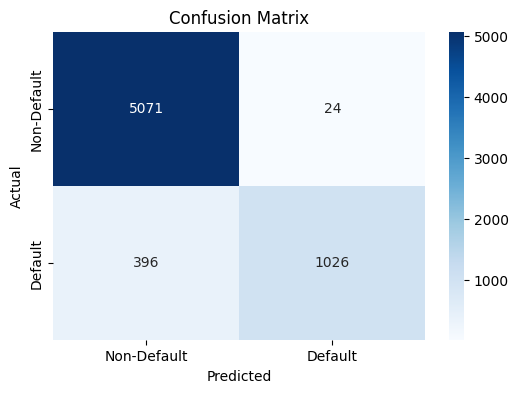

In [8]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Default','Default'], yticklabels=['Non-Default','Default'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

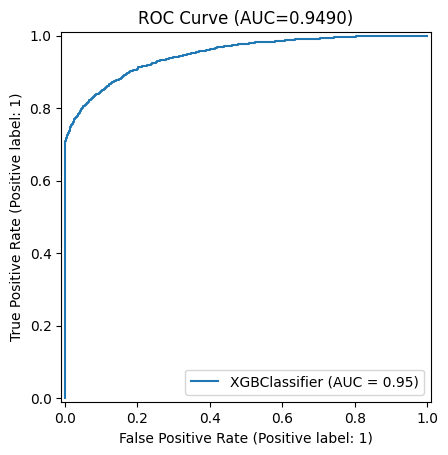

In [9]:
# ROC Curve
roc_auc = roc_auc_score(y_test, y_proba)
RocCurveDisplay.from_estimator(xgb_model, X_test, y_test)
plt.title(f'ROC Curve (AUC={roc_auc:.4f})')
plt.show()

## Step 6: Feature Importance

Top 10 Features by Importance:
                     Feature  Importance
5                 loan_grade    0.241775
8        loan_percent_income    0.220587
2      person_home_ownership    0.220068
4                loan_intent    0.085291
1              person_income    0.066357
7              loan_int_rate    0.046273
3          person_emp_length    0.037890
9  cb_person_default_on_file    0.027805
6                  loan_amnt    0.022670
0                 person_age    0.018403


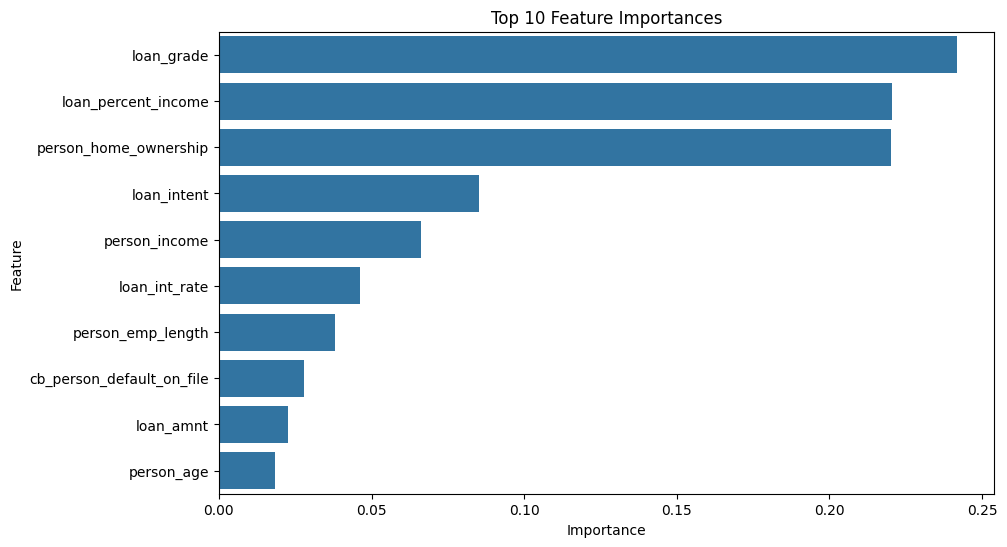

In [10]:

# Step 6: Feature Importance

feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 Features by Importance:")
print(feature_importances.head(10))

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=feature_importances.head(10))
plt.title('Top 10 Feature Importances')
plt.show()

# Step 7: Partial Dependence Plots

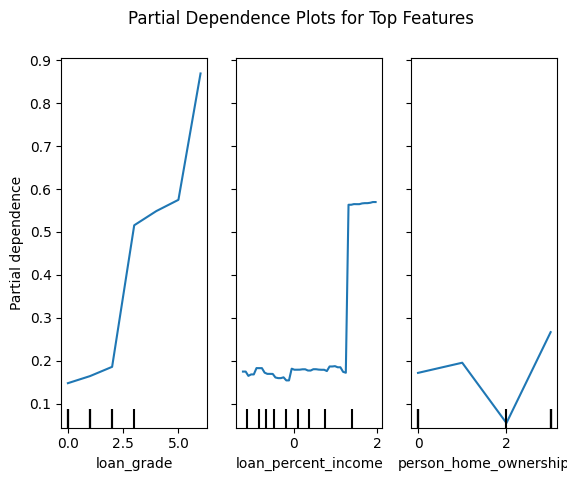

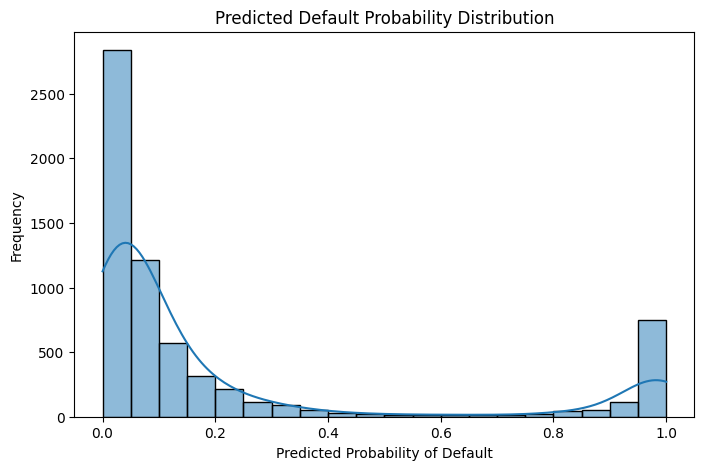

In [11]:
# Step 7: Partial Dependence Plots
top_features = feature_importances['Feature'].head(3).tolist()
PartialDependenceDisplay.from_estimator(xgb_model, X_test, top_features, kind='average', grid_resolution=50)
plt.suptitle('Partial Dependence Plots for Top Features')
plt.show()

# Step 8: Predicted Probability Distribution
plt.figure(figsize=(8,5))
sns.histplot(y_proba, bins=20, kde=True)
plt.title('Predicted Default Probability Distribution')
plt.xlabel('Predicted Probability of Default')
plt.ylabel('Frequency')
plt.show()

## Step 9: Custom Prediction Function

In [ ]:
# Step 9: Custom Prediction Function
# ----------------------------------
def predict_credit_risk(input_df, model, scaler, label_encoders):
    df_copy = input_df.copy()
    
    # Encode categorical features (handle unseen labels safely)
    for col, le in label_encoders.items():
        if col in df_copy.columns:
            df_copy[col] = df_copy[col].map(lambda s: le.transform([s])[0] if s in le.classes_ else -1)
    
    # Scale numerical features
    df_copy[numerical_cols] = scaler.transform(df_copy[numerical_cols])
    
    # Predict probabilities and labels
    df_copy['predicted_proba'] = model.predict_proba(df_copy)[:, 1]
    df_copy['predicted_label'] = model.predict(df_copy)
    
    return df_copy
# Example: new_predictions = predict_credit_risk(df_test_sample, xgb_model, scaler, label_encoders)


## Step 10: Advanced Visualizations

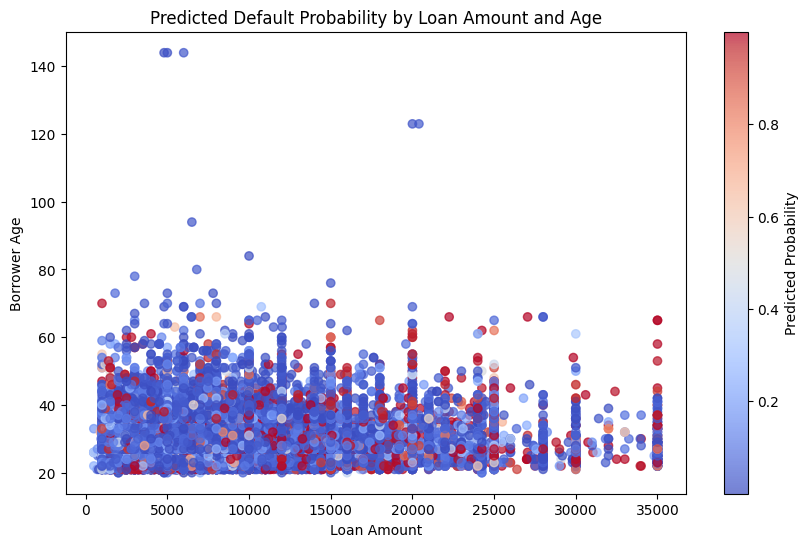

In [13]:
# Step 10: Advanced Visualizations
df['predicted_proba'] = xgb_model.predict_proba(X)[:, 1]
df['application_order'] = np.arange(len(df))  # proxy for time

# Scatter: Loan Amount vs Age
plt.figure(figsize=(10,6))
scatter = plt.scatter(df['loan_amnt'], df['person_age'], c=df['predicted_proba'], cmap='coolwarm', alpha=0.7)
plt.colorbar(scatter, label='Predicted Probability')
plt.xlabel('Loan Amount')
plt.ylabel('Borrower Age')
plt.title('Predicted Default Probability by Loan Amount and Age')
plt.show()


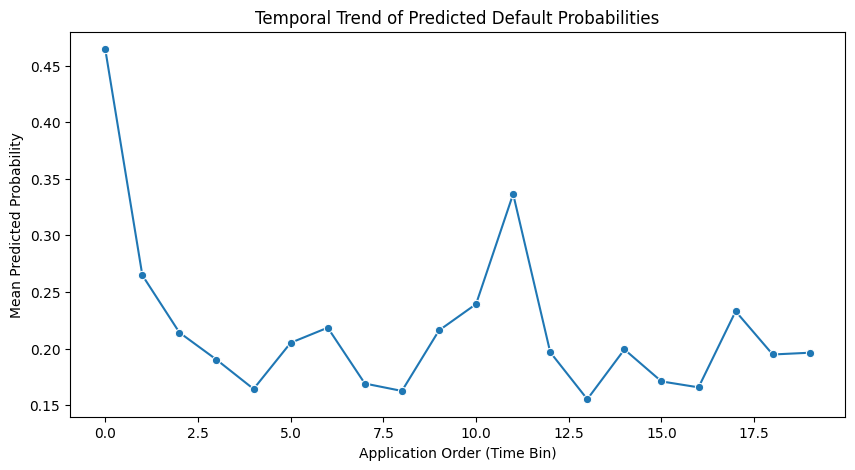

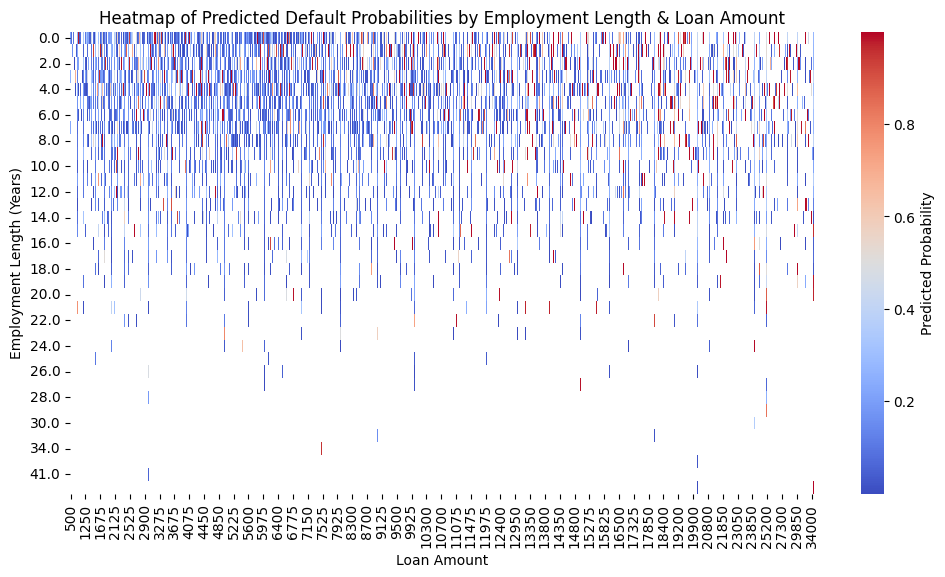

In [14]:
# Temporal trend
df['time_bin'] = pd.qcut(df['application_order'], 20, labels=False)
temporal_probs = df.groupby('time_bin')['predicted_proba'].mean()

plt.figure(figsize=(10,5))
sns.lineplot(x=temporal_probs.index, y=temporal_probs.values, marker='o')
plt.title('Temporal Trend of Predicted Default Probabilities')
plt.xlabel('Application Order (Time Bin)')
plt.ylabel('Mean Predicted Probability')
plt.show()

# Heatmap: Employment Length vs Loan Amount
heatmap_data = df.pivot_table(
    index='person_emp_length',
    columns='loan_amnt',
    values='predicted_proba',
    aggfunc='mean'
)

plt.figure(figsize=(12,6))
sns.heatmap(heatmap_data, cmap='coolwarm', cbar_kws={'label': 'Predicted Probability'})
plt.title('Heatmap of Predicted Default Probabilities by Employment Length & Loan Amount')
plt.xlabel('Loan Amount')
plt.ylabel('Employment Length (Years)')
plt.show()


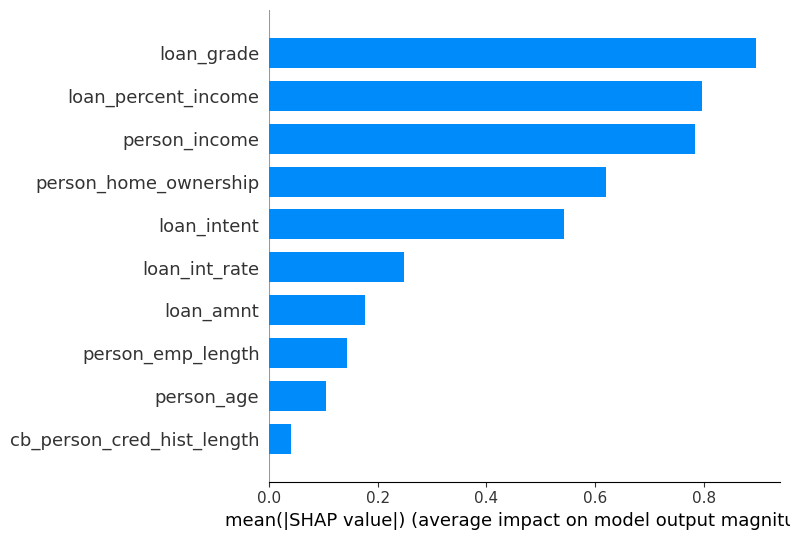

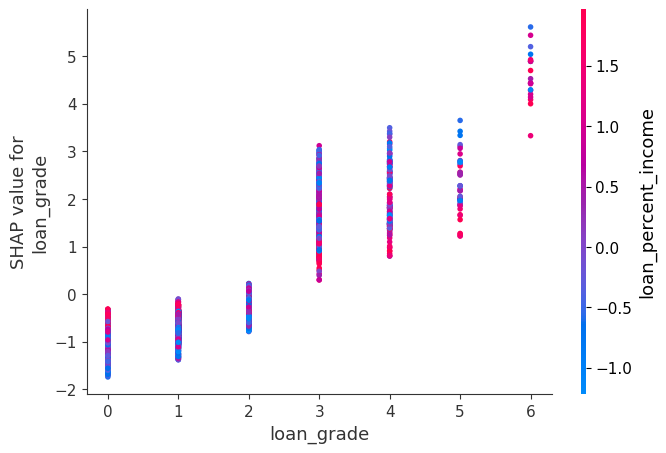

In [15]:
# SHAP visualizations
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

# Summary plot
shap.summary_plot(shap_values, X_test, plot_type="bar", max_display=10)

# Dependence plot for top 2 features
top_feature_1 = feature_importances['Feature'].iloc[0]
top_feature_2 = feature_importances['Feature'].iloc[1]
shap.dependence_plot(top_feature_1, shap_values, X_test, interaction_index=top_feature_2)
